# Proyecto #2: Pipeline de Machine Learning
## Notebook 02: Exploración y selección de la ingeniería de características
### Predict Future Sales (Kaggle)

**Objetivo:** usar los hallazgos del EDA (notebook 01) para decidir:

- **a.** qué *lags* (rezagos) de las ventas mensuales usar como variables del modelo de forecasting;
- **b.** qué operación aplicar en cada uno de los seis procesos de ingeniería de características (imputación numérica, imputación categórica, codificación, outliers, transformación y escalado), con su criterio de selección;
- **c.** la lista final, escrita, de variables y transformaciones que el notebook 03 convertirá en un pipeline de sklearn.

**Variable objetivo:** `item_cnt_month`, las unidades vendidas por mes de cada par tienda-producto (suma de `item_cnt_day` por `date_block_num`). Se predice noviembre de 2015 (`date_block_num` = 34) y la métrica es el RMSE.

**Hallazgos del EDA que se usan aquí:**

| Hallazgo (notebook 01) | Uso en este notebook |
|---|---|
| Precio −1 imputado, 6 duplicados exactos y 3 transacciones extremas eliminadas (4.b, 4.c, 7.c) | Se repiten en `predict_future_sales.dataset.clean_sales` |
| Tiendas duplicadas 0→57, 1→58, 11→10 (4.c) | Operador `Mapper` |
| ACF/PACF mensual: rezago 1 dominante (AR(1)), rezago 2 en la ACF, repunte en el 12 (9) | Lags candidatos |
| Estacionalidad anual: noviembre > octubre, pico en diciembre (6.b.ii) | Rezago 12 y mes del año |
| Solo el 52% de los pares de test tiene historial propio; 363 productos nuevos (10.b) | Lags agregados por producto, tienda y categoría, e indicadores de producto nuevo |

**Memoria:** todas las tablas se construyen con tipos reducidos (`int8`/`int16` para los identificadores y `float32` para las variables numéricas).

In [1]:
import gc
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from predict_future_sales import features as F
from predict_future_sales.dataset import clean_sales, load_raw

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid")
COLOR, COLOR_2 = "#2f6fae", "#d9822b"  # misma paleta del notebook 01

## 1. Construcción de la tabla mensual tienda-producto

### Por qué los lags se construyen fuera del pipeline de sklearn

Un pipeline de sklearn transforma **cada fila por separado**: recibe las columnas de una fila y devuelve sus columnas transformadas. Un lag, en cambio, necesita **el historial** del par tienda-producto: para la fila de noviembre de 2015 hay que buscar las ventas del mismo par en octubre (lag 1), septiembre (lag 2), etc. Esa información no está en `test.csv`, que solo trae `ID`, `shop_id` e `item_id`.

Por eso la tabla de modelado se construye con la función `build_feature_matrix` del módulo `predict_future_sales/features.py`, y esa **misma función** se reutiliza en los notebooks 03, 04 y 05. Así, las filas de entrenamiento, de validación y de test (mes 34) se generan con exactamente el mismo código, y el pipeline de sklearn se encarga solo de los seis procesos de ingeniería de características.

La función realiza, en orden:

1. **Limpieza del EDA** (`clean_sales`): imputa el precio negativo, elimina duplicados exactos y las 3 transacciones extremas.
2. **Unificación de tiendas** con el operador `Mapper` (0→57, 1→58, 11→10), para que los lags de las tiendas 57, 58 y 10 incluyan la historia registrada con los IDs anteriores.
3. **Cuadrícula mensual con ceros:** en cada mes, todas las tiendas activas por todos los productos vendidos ese mes (como recomienda el enunciado y la sección 10.b del EDA, porque `test.csv` es una cuadrícula completa de 42 tiendas x 5,100 productos). Se agrega el mes 34 con los pares de test.
4. **Objetivo:** suma mensual de `item_cnt_day`, con 0 en los meses sin ventas.
5. **Variables de catálogo** (mes del año, categoría, ciudad, tipo y subtipo de categoría), **lags** y variables de historia del producto.

**Regla contra la fuga de información:** toda variable de la fila del mes *m* se calcula solo con meses anteriores a *m*. Para el mes 34, los lags salen de los meses 33, 32, 31, etc.

Para elegir los lags, en este notebook se construyen los **12 rezagos candidatos** (1 a 12 meses).

In [2]:
raw = load_raw()
LAGS_CANDIDATOS = list(range(1, 13))

inicio = time.time()
matriz = F.build_feature_matrix(raw, lags=LAGS_CANDIDATOS)
print(f"Tiempo de construcción: {time.time() - inicio:,.0f} s")
print(f"Filas: {len(matriz):,} | columnas: {matriz.shape[1]}")
print(f"Memoria: {matriz.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
print("Meses incluidos:", matriz["date_block_num"].min(), "a", matriz["date_block_num"].max())
print("\nTipos de dato:")
print(matriz.dtypes.astype(str).value_counts().to_string())
matriz.head()

Tiempo de construcción: 39 s
Filas: 6,639,294 | columnas: 28
Memoria: 531 MB
Meses incluidos: 12 a 34

Tipos de dato:
float32     17
int8         7
category     3
int16        1


,date_block_num,shop_id,item_id,item_cnt_month,month,item_category_id,shop_city,item_cat_type,item_cat_subtype,item_cnt_month_lag_1,item_cnt_month_lag_2,item_cnt_month_lag_3,item_cnt_month_lag_4,item_cnt_month_lag_5,item_cnt_month_lag_6,item_cnt_month_lag_7,item_cnt_month_lag_8,item_cnt_month_lag_9,item_cnt_month_lag_10,item_cnt_month_lag_11,item_cnt_month_lag_12,item_avg_cnt_lag_1,shop_avg_cnt_lag_1,shop_cat_avg_cnt_lag_1,item_price_last,item_age,item_is_new,shop_item_is_new
0,12,54,10297,4.0000,1,37,Химки,Кино,Blu-Ray,3.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.9130,0.9894,0.5859,741.5607,2,0,0
1,12,54,10296,3.0000,1,38,Химки,Кино,Blu-Ray 3D,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.5217,0.9894,0.5519,"1,599.0000",1,0,1
2,12,54,10298,14.0000,1,40,Химки,Кино,DVD,20.0000,20.0000,7.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.2174,0.9894,0.8230,392.3475,3,0,0
3,12,54,10300,3.0000,1,37,Химки,Кино,Blu-Ray,1.0000,20.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.1739,0.9894,0.5859,682.0333,3,0,0
4,12,54,10284,1.0000,1,57,Химки,Музыка,MP3,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,NaN,NaN,0.0870,0.9894,0.4554,266.0000,10,0,0


**Interpretación de la tabla mensual:**

- La tabla tiene **6,639,294 filas**: los meses 12 a 33 de la cuadrícula tienda x producto más las 214,200 filas del mes 34 (los pares de test). Los meses 0 a 11 se usan para calcular los lags, pero no se conservan como filas de entrenamiento, porque en ellos no existe todavía el lag de 12 meses.
- Gracias a los tipos reducidos (`int8` para `date_block_num`, `shop_id`, `month` e `item_category_id`, `int16` para `item_id`, `float32` para los lags y `category` para los textos), la tabla ocupa unos **531 MB aun con los 12 lags candidatos**. Con `int64`/`float64` y textos como `object` ocuparía más del doble.
- Cada fila es un par tienda-producto en un mes, con el objetivo `item_cnt_month`, las variables de catálogo y los lags. En las primeras filas se ve cómo funcionan los lags: el producto 10298 en la tienda 54 vendió 14 unidades en el mes 12, y sus lags 1 y 2 valen 20 (el máximo después del recorte), mientras que los lags más lejanos son NaN porque el producto todavía no se vendía en esa tienda.

In [3]:
# Composición del objetivo en los meses con historia (12 a 33) y en el mes de test (34)
historico = matriz["date_block_num"] < F.TEST_MONTH
y_hist = matriz.loc[historico, F.TARGET]
print(f"Filas de entrenamiento + validación (meses 12-33): {historico.sum():,}")
print(f"Filas del mes 34 (pares de test): {(~historico).sum():,}")
print(f"% de filas con objetivo = 0: {(y_hist == 0).mean() * 100:.2f}%")
print(f"% de filas con objetivo = 20 (valor recortado): {(y_hist == 20).mean() * 100:.2f}%")
print(f"Media del objetivo: {y_hist.mean():.4f} | desviación estándar: {y_hist.std():.4f}")
print("Objetivo del mes 34 (debe ser todo NaN):", matriz.loc[~historico, F.TARGET].isna().all())

Filas de entrenamiento + validación (meses 12-33): 6,425,094
Filas del mes 34 (pares de test): 214,200
% de filas con objetivo = 0: 85.69%
% de filas con objetivo = 20 (valor recortado): 0.10%
Media del objetivo: 0.2877 | desviación estándar: 1.1863
Objetivo del mes 34 (debe ser todo NaN): True


In [4]:
# Verificación contra fuga de información: el lag k del mes m debe ser exactamente el objetivo del mes m-k
anterior = matriz[[*F.KEYS, F.TARGET]].copy()
for k in [1, 2, 6, 12]:
    # Solo meses cuyo mes m-k también está en la tabla (la tabla empieza en el mes 12)
    muestra = matriz[matriz["date_block_num"].between(F.FIRST_MODEL_MONTH + k, F.TEST_MONTH)].sample(20_000, random_state=42)
    desplazado = anterior.copy()
    desplazado["date_block_num"] = (desplazado["date_block_num"] + k).astype("int8")
    comp = muestra[[*F.KEYS, f"{F.TARGET}_lag_{k}"]].merge(desplazado, on=F.KEYS, how="left")
    iguales = np.allclose(comp[f"{F.TARGET}_lag_{k}"].fillna(-1), comp[F.TARGET].fillna(-1))
    print(f"lag {k:>2}: coincide con el objetivo del mes m-{k} en las 20,000 filas de muestra -> {iguales}")
del anterior, muestra, desplazado, comp
gc.collect();

lag  1: coincide con el objetivo del mes m-1 en las 20,000 filas de muestra -> True


lag  2: coincide con el objetivo del mes m-2 en las 20,000 filas de muestra -> True


lag  6: coincide con el objetivo del mes m-6 en las 20,000 filas de muestra -> True


lag 12: coincide con el objetivo del mes m-12 en las 20,000 filas de muestra -> True


**Interpretación de la composición del objetivo y de la verificación de fuga:**

- El **85.69%** de las filas de los meses 12 a 33 tiene `item_cnt_month` = 0. Esto confirma lo que anticipó el EDA (sección 10.b): la mayoría de los pares tienda-producto no vende en un mes dado, y por eso la cuadrícula se rellena con ceros; si se usaran solo los meses con venta, el modelo sobreestimaría las ventas de noviembre.
- Solo el 0.10% de las filas queda en el valor recortado de 20, así que el recorte a [0, 20] afecta a muy pocos pares (se analiza en la sección 3.iv). La media del objetivo es 0.29 unidades y su desviación estándar 1.19: este último valor es, aproximadamente, el RMSE de un modelo que siempre predijera la media.
- El objetivo del mes 34 es NaN en todas las filas, como debe ser: noviembre de 2015 es el mes desconocido.
- **No hay fuga de información:** en muestras de 20,000 filas, los lags 1, 2, 6 y 12 coinciden exactamente con el objetivo del mismo par 1, 2, 6 y 12 meses antes. Cada lag usa solo meses anteriores al de la fila; para el mes 34, el lag 1 es octubre de 2015 (mes 33), el lag 2 septiembre, etc.

## 2. (a) Selección de los lags

Los lags se evalúan **solo con los meses de entrenamiento (12 a 26)**, para no usar información del periodo de validación (27 a 33) al tomar decisiones. Se usan tres criterios:

1. **Correlación** de cada lag con el objetivo (los NaN se toman como 0, porque significan que el par no vendió ese mes).
2. **Cobertura:** porcentaje de filas en las que el par existía en la cuadrícula de ese mes.
3. **Aporte incremental:** RMSE de una regresión lineal con conjuntos de lags cada vez más amplios. Un lag vale la pena si reduce el RMSE cuando ya están los anteriores, que es la idea de la PACF del EDA, pero a nivel de par tienda-producto.

In [5]:
TRAIN = matriz["date_block_num"].between(F.FIRST_MODEL_MONTH, F.LAST_TRAIN_MONTH)
cols_lag = [f"{F.TARGET}_lag_{k}" for k in LAGS_CANDIDATOS]
datos = matriz.loc[TRAIN, [F.TARGET] + cols_lag]
y = datos[F.TARGET].to_numpy(np.float64)

tabla_lags = pd.DataFrame(
    {
        "correlación con el objetivo": [datos[F.TARGET].corr(datos[c].fillna(0)) for c in cols_lag],
        "% filas con el par en la cuadrícula": [datos[c].notna().mean() * 100 for c in cols_lag],
    },
    index=pd.Index(LAGS_CANDIDATOS, name="lag"),
)
tabla_lags

,correlación con el objetivo,% filas con el par en la cuadrícula
lag,,
1,0.5922,79.3582
2,0.4637,76.2939
3,0.3968,72.9716
4,0.3510,69.5065
5,0.3220,66.1934
6,0.2972,63.2467
7,0.2747,60.3136
8,0.2586,57.2844
9,0.2436,54.3025


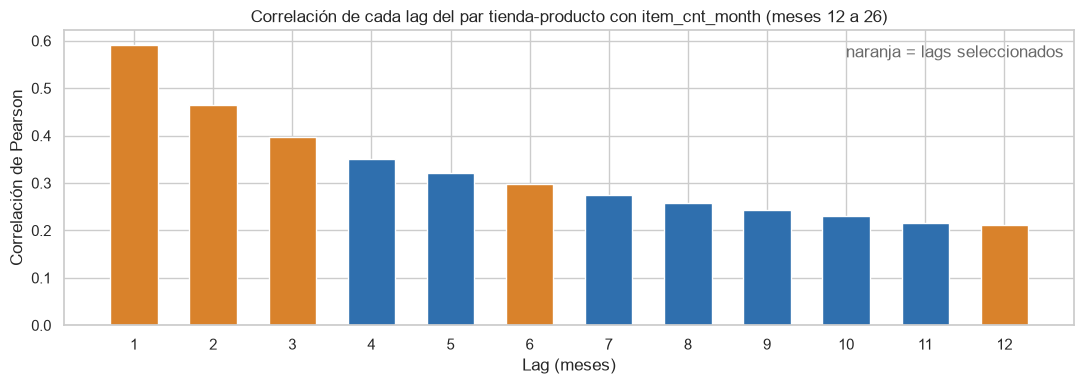

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
colores = [COLOR_2 if k in F.LAGS else COLOR for k in LAGS_CANDIDATOS]
ax.bar(tabla_lags.index, tabla_lags["correlación con el objetivo"], color=colores, width=0.6)
ax.set_xticks(LAGS_CANDIDATOS)
ax.set_xlabel("Lag (meses)")
ax.set_ylabel("Correlación de Pearson")
ax.set_title("Correlación de cada lag del par tienda-producto con item_cnt_month (meses 12 a 26)")
ax.text(0.99, 0.95, "naranja = lags seleccionados", transform=ax.transAxes, ha="right", va="top", color="dimgray")
plt.tight_layout()
plt.show()

In [7]:
def rmse_regresion(columnas):
    """RMSE de una regresión lineal (mínimos cuadrados) del objetivo sobre los lags indicados."""
    X = np.column_stack([np.ones(len(datos))] + [datos[c].fillna(0).to_numpy(np.float64) for c in columnas])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    return np.sqrt(np.mean((X @ beta - y) ** 2))

conjuntos = {
    "sin lags (solo la media)": [],
    "1": [1],
    "1, 2": [1, 2],
    "1, 2, 3": [1, 2, 3],
    "1 a 6": list(range(1, 7)),
    "1 a 12": list(range(1, 13)),
    "1, 2, 3, 6": [1, 2, 3, 6],
    "1, 2, 3, 6, 12": [1, 2, 3, 6, 12],
}
inc = pd.DataFrame(
    {"lags": list(conjuntos), "RMSE (meses 12-26)": [rmse_regresion([f"{F.TARGET}_lag_{k}" for k in v]) for v in conjuntos.values()]}
).set_index("lags")
inc["mejora vs fila anterior"] = -inc["RMSE (meses 12-26)"].diff()
inc["mejora vs lags 1, 2, 3"] = inc.loc["1, 2, 3", "RMSE (meses 12-26)"] - inc["RMSE (meses 12-26)"]
display(inc)

# El lag 12 es el que lleva la estacionalidad anual: su correlación se revisa por mes del año
por_mes = datos.assign(month=matriz.loc[TRAIN, "month"]).groupby("month").apply(
    lambda g: pd.Series({
        "corr lag 1": g[F.TARGET].corr(g[f"{F.TARGET}_lag_1"].fillna(0)),
        "corr lag 12": g[F.TARGET].corr(g[f"{F.TARGET}_lag_12"].fillna(0)),
    }), include_groups=False,
)
print("Correlación del lag 1 y del lag 12 con el objetivo según el mes del año (meses 12 a 26):")
display(por_mes.round(4))

,RMSE (meses 12-26),mejora vs fila anterior,"mejora vs lags 1, 2, 3"
lags,,,
sin lags (solo la media),1.2184,NaN,-0.2567
1,0.9818,0.2366,-0.0200
"1, 2",0.9675,0.0143,-0.0057
"1, 2, 3",0.9617,0.0057,0.0000
1 a 6,0.9560,0.0058,0.0058
1 a 12,0.9535,0.0024,0.0082
"1, 2, 3, 6",0.9578,-0.0043,0.0039
"1, 2, 3, 6, 12",0.9562,0.0016,0.0055


Correlación del lag 1 y del lag 12 con el objetivo según el mes del año (meses 12 a 26):


,corr lag 1,corr lag 12
month,,
1,0.6972,0.2329
2,0.6160,0.2251
3,0.5749,0.1863
4,0.5485,0.1566
5,0.5556,0.1718
6,0.6545,0.1973
7,0.5926,0.2357
8,0.6147,0.2588
9,0.5185,0.2035


**Interpretación y decisión sobre los lags:**

- **Correlación:** decrece de forma gradual con la distancia, de 0.59 en el lag 1 a 0.46 en el lag 2, 0.40 en el lag 3, 0.30 en el lag 6 y 0.21 en el lag 12. Es el mismo patrón de la ACF del EDA (sección 9): decaimiento gradual dominado por el mes anterior.
- **Cobertura:** cuanto más lejano el lag, menos pares existían en la cuadrícula de ese mes (79% en el lag 1, 63% en el 6 y 47% en el 12), porque muchos productos son recientes. Un lag lejano solo aporta información para los productos con más antigüedad.
- **Aporte incremental:** el lag 1 por sí solo reduce el RMSE de 1.218 a 0.982 (la mejora más grande, igual que la PACF del EDA, que solo tenía significativo el rezago 1). Los lags 2 y 3 agregan mejoras pequeñas pero claras (0.014 y 0.006). A partir de ahí la ganancia se vuelve marginal: usar los 12 lags solo mejora 0.008 frente a los lags 1, 2 y 3, con 9 columnas más.
- **Lag 12:** a nivel de par su aporte lineal es modesto (pasa de 0.9578 a 0.9562 al agregarlo a los lags 1, 2, 3 y 6), y su correlación por mes del año no se concentra en noviembre (0.18). Aun así se conserva, porque es la única variable que conecta cada mes con el mismo mes del año anterior; el EDA mostró que la estacionalidad anual existe (diciembre +41% a +53%, noviembre por encima de octubre) aunque la ACF con 34 meses no alcance a confirmarla. Un modelo de árboles puede combinarlo con `month` de forma no lineal.

**Decisión: lags 1, 2, 3, 6 y 12** del par tienda-producto (`F.LAGS`). Con 5 columnas se obtiene un RMSE (0.9562) prácticamente igual al de los lags 1 a 6 (0.9560) y cercano al de los 12 lags (0.9535): los lags 1, 2 y 3 capturan la dependencia de corto plazo (AR), el 6 la tendencia de medio año, y el 12 la estacionalidad anual.

### Lags agregados y variables de historia

El EDA mostró que casi la mitad de los pares de test no tiene historial propio (sección 10.b). Para esos pares, los lags del par son NaN o cero, así que se necesitan variables de **nivel superior**, todas rezagadas un mes para no usar información del mes que se predice:

- `item_avg_cnt_lag_1`: venta media del producto en todas las tiendas el mes anterior.
- `shop_avg_cnt_lag_1`: venta media de la tienda (por producto) el mes anterior.
- `shop_cat_avg_cnt_lag_1`: venta media de la categoría en esa tienda el mes anterior.
- `item_price_last`: último precio promedio conocido del producto antes del mes.
- `item_age`: meses desde la primera venta del producto; `item_is_new` y `shop_item_is_new`: indicadores de producto o par sin ventas previas.

In [8]:
extra = ["item_avg_cnt_lag_1", "shop_avg_cnt_lag_1", "shop_cat_avg_cnt_lag_1", "item_price_last",
         "item_age", "item_is_new", "shop_item_is_new", "month"]
entreno = matriz.loc[TRAIN]
corr_extra = pd.DataFrame(
    {
        "correlación (todas las filas)": [entreno[F.TARGET].corr(entreno[c].astype("float32").fillna(0)) for c in extra],
        "correlación (pares sin historial)": [
            entreno.loc[entreno["shop_item_is_new"] == 1, F.TARGET].corr(
                entreno.loc[entreno["shop_item_is_new"] == 1, c].astype("float32").fillna(0)
            )
            for c in extra
        ],
        "% NaN": [entreno[c].isna().mean() * 100 for c in extra],
    },
    index=extra,
)
display(corr_extra)

print("Venta media según si el par o el producto tienen historia:")
display(
    entreno.groupby(["item_is_new", "shop_item_is_new"])[F.TARGET]
    .agg(filas="size", venta_media="mean", pct_con_venta=lambda s: (s > 0).mean() * 100)
)
del entreno

,correlación (todas las filas),correlación (pares sin historial),% NaN
item_avg_cnt_lag_1,0.4930,0.0507,19.8748
shop_avg_cnt_lag_1,0.1704,0.1047,0.9707
shop_cat_avg_cnt_lag_1,0.4336,0.2825,1.0453
item_price_last,0.0459,-0.0223,4.9350
item_age,-0.0991,-0.1464,0.0000
item_is_new,0.0707,0.2154,0.0000
shop_item_is_new,-0.1397,NaN,0.0000
month,0.0121,0.0326,0.0000


Venta media según si el par o el producto tienen historia:


filas  venta_media  pct_con_venta
item_is_new shop_item_is_new                                     
0           0                 2512211       0.4592        22.6797
            1                 2061110       0.0545         3.8550
1           1                  237409       0.6746        19.1008

**Interpretación de los lags agregados y de las variables de historia:**

- `item_avg_cnt_lag_1` (venta media del producto en todas las tiendas el mes anterior) tiene una correlación de **0.49**, casi tan alta como el lag 1 del propio par, y `shop_cat_avg_cnt_lag_1` llega a 0.43. Son la vía para que el modelo aprenda del comportamiento del producto en otras tiendas y de la categoría en la tienda.
- Para los **pares sin historial propio** (`shop_item_is_new` = 1, el caso del 48% de los pares de test), la variable más útil es `shop_cat_avg_cnt_lag_1` (0.28) y la bandera `item_is_new` (0.22). La correlación de `shop_item_is_new` en ese grupo es NaN porque dentro de él la variable es constante.
- La tabla de venta media separa tres situaciones muy distintas: los pares con historia venden en promedio 0.46 unidades (23% con alguna venta); los productos conocidos que nunca se vendieron en esa tienda, solo 0.05 (3.9% con venta); y los productos nuevos, 0.67 (19% con venta), porque los lanzamientos venden fuerte en su primer mes. Por eso las banderas `item_is_new` y `shop_item_is_new` son importantes.
- **Precaución:** en el entrenamiento un producto nuevo solo aparece en la cuadrícula si se vendió en alguna tienda ese mes, mientras que en test los 363 productos nuevos aparecen en las 42 tiendas aunque no se vendan. El modelo podría sobreestimar un poco estos pares; se revisará en el notebook 05.
- `month` casi no se correlaciona linealmente con el objetivo (0.01), lo esperable para una variable cíclica; se conserva para los modelos de árboles, que pueden aprender su efecto no lineal.

In [9]:
# Se conservan solo los lags elegidos para liberar memoria
no_elegidos = [f"{F.TARGET}_lag_{k}" for k in LAGS_CANDIDATOS if k not in F.LAGS]
matriz = matriz.drop(columns=no_elegidos)
del datos, y
gc.collect()
print("Lags conservados:", F.pair_lag_features())
print(f"Memoria de la tabla: {matriz.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

# Datos de entrenamiento sobre los que se ajustan (fit) todas las transformaciones de la sección 3
X_train, y_train = F.split_xy(matriz, range(F.FIRST_MODEL_MONTH, F.LAST_TRAIN_MONTH + 1))
print(f"X_train: {X_train.shape[0]:,} filas x {X_train.shape[1]} columnas")

Lags conservados: ['item_cnt_month_lag_1', 'item_cnt_month_lag_2', 'item_cnt_month_lag_3', 'item_cnt_month_lag_6', 'item_cnt_month_lag_12']
Memoria de la tabla: 345 MB


X_train: 4,810,730 filas x 20 columnas


## 3. (b) Procesos de ingeniería de características

Cada proceso se analiza con el mismo esquema: **diagnóstico** (qué variables lo necesitan), **operación elegida y criterio**, y **aplicación** con la clase de `feature-engine` correspondiente. Todas las transformaciones se **ajustan solo con los meses de entrenamiento (12 a 26)**, para que los parámetros aprendidos (medianas, modas, límites, codificaciones) no contengan información del periodo de validación ni del mes de test. Las transformaciones se aplican en cadena sobre una copia (`demo`), en el mismo orden que tendrá el pipeline.

In [10]:
demo = X_train.copy()
faltantes = (demo.isna().mean() * 100).rename("% NaN")
faltantes = faltantes[faltantes > 0].sort_values(ascending=False).to_frame()
faltantes["tipo"] = ["categórica" if str(demo[c].dtype) == "category" else "numérica" for c in faltantes.index]
faltantes

,% NaN,tipo
item_cnt_month_lag_12,53.3668,numérica
item_cnt_month_lag_6,36.7533,numérica
item_cnt_month_lag_3,27.0284,numérica
item_cnt_month_lag_2,23.7061,numérica
item_cnt_month_lag_1,20.6418,numérica
item_avg_cnt_lag_1,19.8748,numérica
item_price_last,4.9350,numérica
shop_city,4.2286,categórica
shop_cat_avg_cnt_lag_1,1.0453,numérica
shop_avg_cnt_lag_1,0.9707,numérica


**Diagnóstico de valores faltantes:** a diferencia del dataset original, que no tenía nulos (EDA, sección 4.a), la tabla de modelado sí los tiene, y todos son **estructurales** (se explican por cómo se construyen las variables, no por errores de captura):

- **Numéricas:** los lags del par (21% a 53%), el lag agregado del producto (20%), los de tienda y tienda-categoría (1%) y el precio previo (4.9%).
- **Categóricas:** la ciudad (4.2%) y el subtipo de categoría (0.3%).

Por lo tanto, **no es necesario forzar** faltantes de forma aleatoria: los procesos de imputación numérica y categórica se aplican sobre faltantes reales.

### 3.i Imputación de variables numéricas

In [11]:
from feature_engine.imputation import ArbitraryNumberImputer, MeanMedianImputer

# ¿Qué significa un NaN en los lags? Que el par (o el producto, la tienda o la categoría) no estuvo
# en la cuadrícula de ese mes, es decir, que no tuvo ventas.
print("Valores mínimos de los lags (sin contar NaN):")
print(demo[F.count_lag_features()].min().to_string())

# ¿Quiénes no tienen precio previo? Se espera que sean solo productos sin ventas anteriores
sin_precio = demo["item_price_last"].isna()
print(f"\nFilas sin item_price_last: {sin_precio.sum():,}")
print(f"De ellas, con item_is_new = 1: {demo.loc[sin_precio, 'item_is_new'].mean() * 100:.1f}%")

precio = demo["item_price_last"].dropna()
print(f"\nitem_price_last -> media: {precio.mean():,.2f} | mediana: {precio.median():,.2f} | asimetría: {precio.skew():.2f}")

Valores mínimos de los lags (sin contar NaN):
item_cnt_month_lag_1     0.0000
item_cnt_month_lag_2     0.0000
item_cnt_month_lag_3     0.0000
item_cnt_month_lag_6     0.0000
item_cnt_month_lag_12    0.0000
item_avg_cnt_lag_1       0.0000
shop_avg_cnt_lag_1       0.0003
shop_cat_avg_cnt_lag_1   0.0000

Filas sin item_price_last: 237,409
De ellas, con item_is_new = 1: 100.0%



item_price_last -> media: 684.77 | mediana: 299.00 | asimetría: 9.52


In [12]:
imp_cnt = ArbitraryNumberImputer(arbitrary_number=0, variables=F.count_lag_features())
imp_precio = MeanMedianImputer(imputation_method="median", variables=F.PRICE_FEATURES)

demo = imp_cnt.fit_transform(demo)
demo = imp_precio.fit_transform(demo)
print("Valor imputado en los lags:", imp_cnt.imputer_dict_[F.count_lag_features()[0]])
print("Mediana aprendida para item_price_last:", imp_precio.imputer_dict_)
print("NaN restantes en variables numéricas:", demo.select_dtypes("number").isna().sum().sum())

Valor imputado en los lags: 0
Mediana aprendida para item_price_last: {'item_price_last': 299.0}
NaN restantes en variables numéricas: 0


**Criterio y resultado de la imputación numérica:**

- **Lags de conteo → `ArbitraryNumberImputer(arbitrary_number=0)`.** Un NaN en un lag significa que el par (o el producto, la tienda o la categoría) no estuvo en la cuadrícula de ese mes, es decir, que **no tuvo ventas**. El valor correcto es 0, no la media ni la mediana: imputar con la media inventaría ventas que no existieron. Todos los lags tienen mínimo 0, así que el 0 queda dentro del rango natural de la variable.
- **Precio previo → `MeanMedianImputer(imputation_method="median")`.** Las 237,409 filas sin `item_price_last` son, en el 100% de los casos, productos sin ventas anteriores (`item_is_new` = 1): el precio no se conoce porque el producto nunca se vendió. La variable es muy asimétrica (asimetría de 9.5, media de 684.77 frente a mediana de 299), por lo que la **mediana** es un valor más representativo que la media, que está inflada por los productos caros. Se prefirió frente a `RandomSampleImputer` porque esta añade ruido aleatorio y hace que la misma fila reciba precios distintos en cada ejecución. La información de que el producto es nuevo no se pierde, porque ya está en `item_is_new`.
- La mediana aprendida en el entrenamiento es **299** y, después de imputar, no queda ningún NaN numérico.

### 3.ii Imputación de variables categóricas

In [13]:
from feature_engine.imputation import CategoricalImputer

# Tiendas sin ciudad: su nombre no empieza con una ciudad
tiendas = raw["shops"].merge(F.shop_features(raw["shops"]), on="shop_id")
print("Tiendas sin ciudad (shop_city = NaN):")
display(tiendas[tiendas["shop_city"].isna()][["shop_id", "shop_name"]])
print("¿Están en test?:", sorted(set(tiendas.loc[tiendas["shop_city"].isna(), "shop_id"]) & set(raw["test"]["shop_id"])))

# Categorías sin subtipo: su nombre no tiene la forma 'grupo - subgrupo'
cats = raw["item_categories"].merge(F.category_features(raw["item_categories"]), on="item_category_id")
print("\nCategorías sin subtipo (item_cat_subtype = NaN):")
display(cats[cats["item_cat_subtype"].isna()][["item_category_id", "item_category_name", "item_cat_type"]])

Tiendas sin ciudad (shop_city = NaN):


,shop_id,shop_name
9,9,Выездная Торговля
12,12,Интернет-магазин ЧС
55,55,Цифровой склад 1С-Онлайн


¿Están en test?: [12, 55]

Categorías sin subtipo (item_cat_subtype = NaN):


,item_category_id,item_category_name,item_cat_type
8,8,Билеты (Цифра),Билеты
9,9,Доставка товара,Доставка товара
32,32,"Карты оплаты (Кино, Музыка, Игры)",Карты оплаты
79,79,Служебные,Служебные
81,81,Чистые носители (шпиль),Чистые носители
82,82,Чистые носители (штучные),Чистые носители
83,83,Элементы питания,Элементы питания


In [14]:
imp_cat = CategoricalImputer(imputation_method="frequent", variables=["shop_city", "item_cat_subtype"])
demo = imp_cat.fit_transform(demo)
print("Moda aprendida en el entrenamiento:", imp_cat.imputer_dict_)
print("NaN restantes en variables categóricas:", demo[F.CATEGORICAL_FEATURES].isna().sum().sum())

Moda aprendida en el entrenamiento: {'shop_city': 'Москва', 'item_cat_subtype': 'DVD'}
NaN restantes en variables categóricas: 0


**Criterio y resultado de la imputación categórica:**

- **`shop_city`:** las tiendas 9 (Выездная Торговля, venta itinerante), 12 (Интернет-магазин ЧС, tienda en línea) y 55 (Цифровой склад 1С-Онлайн, almacén digital) no tienen una ciudad en su nombre porque no son sucursales físicas. Las tiendas 12 y 55 están en test, así que el pipeline debe saber tratarlas.
- **`item_cat_subtype`:** 7 categorías no tienen la forma "grupo - subgrupo" (boletos, servicio de entrega, tarjetas de pago generales, servicios, discos vírgenes y pilas).
- **Operación: `CategoricalImputer(imputation_method="frequent")`** (moda). Criterio: los faltantes son pocos (4.2% y 0.3% de las filas) y la moda no crea una categoría nueva. La moda aprendida es **Москва** (Moscú) para la ciudad, lo que además es razonable: la tienda en línea y el almacén digital de 1C operan desde Moscú. Para el subtipo la moda es **DVD**; en este caso la información de que la categoría es especial no se pierde, porque se conserva en `item_cat_type` y en `item_category_id`.

### 3.iii Codificación de variables categóricas

El enunciado pide que la **tienda** y el **producto** entren al modelo como variables exógenas o banderas. La tienda entra con `shop_id` (y su ciudad); el producto entra con su categoría (`item_category_id`, tipo y subtipo), sus lags, su precio y sus indicadores de producto nuevo.

In [15]:
cardinalidad = pd.DataFrame(
    {
        "valores distintos (train)": [X_train[c].nunique() for c in ["shop_id", "item_category_id", "shop_city", "item_cat_type", "item_cat_subtype", "item_id"]],
    },
    index=["shop_id", "item_category_id", "shop_city", "item_cat_type", "item_cat_subtype", "item_id"],
)
cardinalidad["tipo en la tabla"] = [str(X_train[c].dtype) for c in cardinalidad.index]
display(cardinalidad)

participacion = X_train["item_cat_type"].value_counts(normalize=True).mul(100).round(2)
print("Participación de cada tipo de categoría en las filas (%):")
print(participacion.head(8).to_string())
print(f"Las 6 más frecuentes cubren el {participacion.head(6).sum():.1f}% de las filas")

nuevos_test = set(raw["test"]["item_id"]) - set(raw["sales"]["item_id"])
print(f"\nProductos de test sin ninguna venta en el train: {len(nuevos_test)} (item_id no se puede aprender para ellos)")

,valores distintos (train),tipo en la tabla
shop_id,53,int8
item_category_id,75,int8
shop_city,28,category
item_cat_type,17,category
item_cat_subtype,53,category
item_id,14946,int16


Participación de cada tipo de categoría en las filas (%):
item_cat_type
Кино         36.8200
Музыка       20.4800
Подарки      13.6600
Игры PC       9.4500
Игры          8.7700
Книги         4.9000
Программы     3.3400
Аксессуары    1.3800
Las 6 más frecuentes cubren el 94.1% de las filas

Productos de test sin ninguna venta en el train: 363 (item_id no se puede aprender para ellos)


In [16]:
from feature_engine.encoding import OneHotEncoder, OrdinalEncoder
from feature_engine.selection import DropFeatures

ord_enc = OrdinalEncoder(
    encoding_method="ordered",
    variables=["shop_id", "item_category_id", "shop_city", "item_cat_subtype"],
    ignore_format=True,  # shop_id e item_category_id son enteros, pero se tratan como categorías
    unseen="encode",     # una categoría no vista en el entrenamiento recibe -1 en lugar de fallar
)
ohe = OneHotEncoder(top_categories=6, variables=["item_cat_type"])
drop = DropFeatures(features_to_drop=["item_id"])

demo = ord_enc.fit_transform(demo, y_train)
demo = ohe.fit_transform(demo)
demo = drop.fit_transform(demo)

# Ejemplo del mapeo ordenado de shop_id: las tiendas con menor venta media reciben los códigos más bajos
mapa_tiendas = pd.Series(ord_enc.encoder_dict_["shop_id"], name="código").sort_values()
venta_media = y_train.groupby(X_train["shop_id"]).mean().rename("venta media (train)")
display(pd.concat([mapa_tiendas, venta_media], axis=1).sort_values("código").iloc[[0, 1, 2, -3, -2, -1]])
print("Columnas creadas por el one-hot:", [c for c in demo.columns if c.startswith("item_cat_type_")])
print("Columnas después de codificar:", demo.shape[1])

,código,venta media (train)
34,0,0.0609
40,1,0.0626
10,2,0.1017
54,50,0.7886
25,51,0.8936
31,52,1.1572


Columnas creadas por el one-hot: ['item_cat_type_Кино', 'item_cat_type_Музыка', 'item_cat_type_Подарки', 'item_cat_type_Игры PC', 'item_cat_type_Игры', 'item_cat_type_Книги']
Columnas después de codificar: 24


**Criterio y resultado de la codificación:**

- **`OrdinalEncoder(encoding_method="ordered")` para `shop_id`, `item_category_id`, `shop_city` e `item_cat_subtype`.** Son variables de cardinalidad media o alta (53 tiendas, 75 categorías, 28 ciudades y 53 subtipos en el entrenamiento). Un one-hot crearía más de 200 columnas en 4.8 millones de filas (varios GB). La codificación *ordenada* asigna los códigos según la venta media de cada categoría en el entrenamiento, de modo que el código tiene una relación monótona con el objetivo y sirve tanto a los árboles como a los modelos lineales. Por ejemplo, la tienda 34 (venta media de 0.06) recibe el código 0 y la tienda 31 (1.16, la más grande según el EDA) el código 52. Así es como **la tienda entra al modelo como variable exógena**. Con `unseen="encode"`, una categoría que no esté en el entrenamiento recibe -1 en lugar de generar un error.
- **`OneHotEncoder(top_categories=6)` para `item_cat_type`.** Tiene baja cardinalidad (17 tipos) y las 6 más frecuentes (Кино, Музыка, Подарки, Игры PC, Игры y Книги) cubren el 94.1% de las filas; el resto queda con todas las columnas en 0. Se crean 6 banderas binarias.
- **`DropFeatures(["item_id"])`.** `item_id` tiene 14,946 valores distintos en el entrenamiento y es un identificador sin orden; además, 363 productos de test nunca se vendieron, así que su identificador no se puede aprender. **El producto entra al modelo como variable exógena** a través de su categoría (`item_category_id`, tipo y subtipo), su precio, su antigüedad, sus banderas de producto nuevo y sus lags agregados.
- Después de codificar quedan 24 columnas, todas numéricas.

### 3.iv Tratamiento de outliers

In [17]:
# Objetivo: ventas mensuales SIN recortar, calculadas a partir de las ventas limpias
ventas = clean_sales(raw["sales"])
mensual = ventas.groupby(["date_block_num", "shop_id", "item_id"])["item_cnt_day"].sum()
pct = mensual.quantile([0.5, 0.9, 0.99, 0.999, 1.0])
print("Percentiles de la venta mensual de los pares con actividad:")
print(pct.rename(index=lambda q: f"p{q * 100:g}").to_string())
print(f"Pares-mes con venta > 20: {(mensual > 20).sum():,} ({(mensual > 20).mean() * 100:.2f}%)")
print(f"Pares-mes con venta neta < 0: {(mensual < 0).sum():,}")
del ventas, mensual
gc.collect();

Percentiles de la venta mensual de los pares con actividad:
p50         1.0000
p90         4.0000
p99        17.0000
p99.9      74.0000
p100    1,644.0000
Pares-mes con venta > 20: 11,462 (0.71%)
Pares-mes con venta neta < 0: 915


In [18]:
from feature_engine.outliers import Winsorizer

precio = demo["item_price_last"]
q1, q3 = precio.quantile([0.25, 0.75])
print(f"item_price_last -> Q1: {q1:,.2f} | Q3: {q3:,.2f} | IQR: {q3 - q1:,.2f} | máximo: {precio.max():,.2f}")
for fold in [1.5, 3]:
    limite = q3 + fold * (q3 - q1)
    print(f"fold = {fold}: límite superior {limite:,.2f} -> filas recortadas {(precio > limite).mean() * 100:.2f}%")

item_price_last -> Q1: 198.00 | Q3: 698.96 | IQR: 500.96 | máximo: 36,990.00
fold = 1.5: límite superior 1,450.41 -> filas recortadas 10.30%
fold = 3: límite superior 2,201.86 -> filas recortadas 4.48%


Límite aprendido: {'item_price_last': 2201.857177734375}


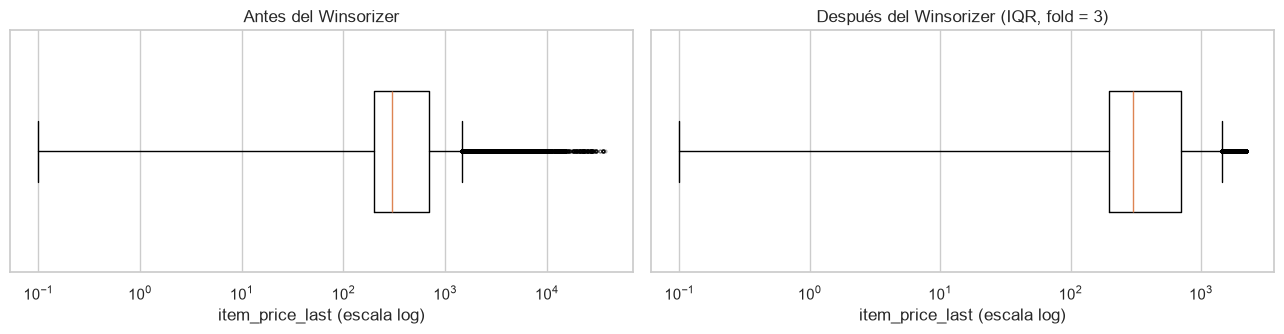

In [19]:
winsor = Winsorizer(capping_method="iqr", tail="right", fold=3, variables=F.PRICE_FEATURES)
antes = demo["item_price_last"].copy()
demo = winsor.fit_transform(demo)
print("Límite aprendido:", winsor.right_tail_caps_)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for ax, serie, titulo in [(axes[0], antes, "Antes del Winsorizer"), (axes[1], demo["item_price_last"], "Después del Winsorizer (IQR, fold = 3)")]:
    ax.boxplot(serie.sample(200_000, random_state=0), orientation="horizontal", widths=0.5, flierprops={"markersize": 2, "alpha": 0.3})
    ax.set_xscale("log")
    ax.set_title(titulo)
    ax.set_xlabel("item_price_last (escala log)")
    ax.set_yticks([])
plt.tight_layout()
plt.show()

**Criterio y resultado del tratamiento de outliers:**

> **Por qué fold = 3 y no 1.5:** con 1.5 el límite (1,450) recortaría el 10.3% de las filas y borraría la diferencia real de precio entre juegos y consolas; con 3 el límite (2,201.86) solo afecta al 4.48% de las filas, que son los precios realmente extremos.

- **Objetivo (`item_cnt_month`) → recorte a [0, 20].** La venta mensual de los pares con actividad tiene mediana 1, p99 de 17 y p99.9 de 74, con un máximo de 1,644 (incluso después de eliminar las 3 transacciones extremas del EDA). Solo el 0.71% de los pares-mes supera 20 unidades, y 915 tienen ventas netas negativas por devoluciones. La competencia evalúa con los valores reales recortados a [0, 20], así que se aplica el **mismo recorte** al objetivo de entrenamiento: evita que unos pocos lanzamientos o ventas al mayoreo dominen el error cuadrático. Como es una operación sobre `y`, se hace en `build_feature_matrix` (los pasos de un pipeline de sklearn solo transforman `X`) y las predicciones finales también se recortan a [0, 20].
- **Precio previo (`item_price_last`) → `Winsorizer(capping_method="iqr", tail="right", fold=3)`.** El EDA (sección 7.c) mostró una cola derecha muy larga por consolas, licencias y ediciones de colección (el máximo es 36,990, frente a un Q3 de 699). Con el criterio IQR clásico (fold = 1.5) el límite sería 1,450 y se recortaría el 10.3% de las filas, lo que eliminaría la diferencia entre juegos y consolas, que es información real. Con **fold = 3** el límite sube a **2,201.86** y solo se recorta el 4.48% de las filas, que son los precios realmente extremos. Solo se recorta la cola derecha porque no hay precios extremadamente bajos que sean errores (el precio negativo se corrigió en la limpieza).
- Los boxplots muestran que, después del Winsorizer, los puntos aislados a la derecha desaparecen y la distribución termina en el límite aprendido.
- Los lags no se recortan: ya provienen del objetivo recortado a [0, 20], y aplicarles el criterio IQR sería un error, porque su Q1 y su Q3 valen 0 y todo valor positivo se consideraría outlier.

### 3.v Transformación de variables numéricas

In [20]:
from feature_engine.transformation import LogCpTransformer, LogTransformer, YeoJohnsonTransformer

cols_transf = F.PRICE_FEATURES + F.count_lag_features()
print("Asimetría antes de transformar:")
asim_antes = demo[cols_transf].skew()
print(asim_antes.round(2).to_string())

# Prueba de Yeo-Johnson en una muestra de 300,000 filas (el ajuste en todo el train es muy lento)
muestra = demo[F.count_lag_features()].sample(300_000, random_state=42)
inicio = time.time()
yj = YeoJohnsonTransformer(variables=F.count_lag_features()).fit(muestra)
print(f"\nYeo-Johnson en 300,000 filas: {time.time() - inicio:,.1f} s")
print("Lambdas estimadas:", {k: round(float(v), 2) for k, v in yj.lambda_dict_.items()})
print("Valores distintos de item_cnt_month_lag_1 tras Yeo-Johnson:",
      np.unique(yj.transform(muestra)["item_cnt_month_lag_1"].round(4))[:8])

Asimetría antes de transformar:
item_price_last           1.7000
item_cnt_month_lag_1      9.1500
item_cnt_month_lag_2      9.1600
item_cnt_month_lag_3      9.2500
item_cnt_month_lag_6      9.5700
item_cnt_month_lag_12    10.0800
item_avg_cnt_lag_1        9.2800
shop_avg_cnt_lag_1        2.3100
shop_cat_avg_cnt_lag_1   12.5200



Yeo-Johnson en 300,000 filas: 19.0 s
Lambdas estimadas: {'item_cnt_month_lag_1': -5.96, 'item_cnt_month_lag_2': -5.96, 'item_cnt_month_lag_3': -5.96, 'item_cnt_month_lag_6': -5.96, 'item_cnt_month_lag_12': -5.96, 'item_avg_cnt_lag_1': -3.9, 'shop_avg_cnt_lag_1': -3.63, 'shop_cat_avg_cnt_lag_1': -3.17}
Valores distintos de item_cnt_month_lag_1 tras Yeo-Johnson: [0.     0.1652 0.1677 0.1679]


                        asimetría antes  asimetría después
item_price_last                  1.7000             0.0700
item_cnt_month_lag_1             9.1500             3.4000
item_cnt_month_lag_2             9.1600             3.4300
item_cnt_month_lag_3             9.2500             3.4900
item_cnt_month_lag_6             9.5700             3.6300
item_cnt_month_lag_12           10.0800             4.0600
item_avg_cnt_lag_1               9.2800             3.4400
shop_avg_cnt_lag_1               2.3100             1.7000
shop_cat_avg_cnt_lag_1          12.5200             2.5100


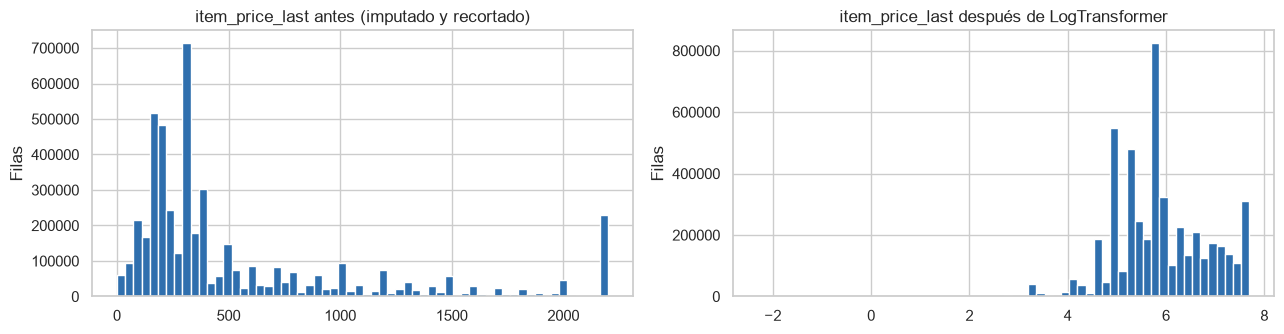

In [21]:
log_precio = LogTransformer(variables=F.PRICE_FEATURES)
log_conteos = LogCpTransformer(variables=F.count_lag_features(), C=1)  # log(x + 1), admite ceros

antes_precio = demo["item_price_last"].copy()
demo = log_precio.fit_transform(demo)
demo = log_conteos.fit_transform(demo)

print(pd.DataFrame({"asimetría antes": asim_antes, "asimetría después": demo[cols_transf].skew()}).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].hist(antes_precio, bins=60, color=COLOR)
axes[0].set_title("item_price_last antes (imputado y recortado)")
axes[1].hist(demo["item_price_last"], bins=60, color=COLOR)
axes[1].set_title("item_price_last después de LogTransformer")
for ax in axes:
    ax.set_ylabel("Filas")
plt.tight_layout()
plt.show()

**Criterio y resultado de la transformación de variables numéricas:**

- **Yeo-Johnson se descartó.** Ajustarlo en solo 300,000 filas tardó más de 15 segundos (unos 5 minutos en todo el entrenamiento) y las lambdas estimadas son extremas (-5.96 en los lags del par): como más del 80% de los valores son 0, la transformación óptima aplasta todos los valores positivos casi en el mismo número (0.165, 0.168, ...), es decir, convierte el lag en una variable casi binaria y destruye la diferencia entre vender 1 o 20 unidades.
- **`LogTransformer` para `item_price_last`.** Es una variable estrictamente positiva con sesgo a la derecha; el logaritmo reduce su asimetría de 1.70 a **0.07**, como se ve en los histogramas: la distribución pasa de estar concentrada a la izquierda a ser aproximadamente simétrica.
- **`LogCpTransformer(C=1)`, es decir, log(x + 1), para los 8 lags de conteo.** Admite ceros (log(0 + 1) = 0), conserva el orden y comprime la cola: la asimetría de los lags del par baja de 9 a 10 a entre 3.4 y 4.1, y la de `shop_cat_avg_cnt_lag_1` de 12.5 a 2.5. Es la transformación natural para conteos, es rápida y no tiene parámetros que estimar. La asimetría restante se debe a la gran proporción de ceros, que ninguna transformación monótona puede eliminar.

### 3.vi Escalado de características

In [22]:
from feature_engine.wrappers import SklearnTransformerWrapper
from sklearn.preprocessing import StandardScaler

columnas_muestra = ["shop_id", "item_price_last", "item_cnt_month_lag_1", "item_age", "date_block_num"]
print("Antes del escalado:")
display(demo[columnas_muestra].describe().loc[["mean", "std", "min", "max"]])

scaler = SklearnTransformerWrapper(transformer=StandardScaler())
demo = scaler.fit_transform(demo)
print("Después del escalado (StandardScaler sobre todas las columnas):")
display(demo[columnas_muestra].describe().loc[["mean", "std", "min", "max"]])
print("Variables escaladas:", len(scaler.variables_))

Antes del escalado:


,shop_id,item_price_last,item_cnt_month_lag_1,item_age,date_block_num
mean,26.1393,5.8836,0.1392,11.9892,18.7966
std,14.7448,0.9340,0.3870,7.0726,4.2886
min,0.0000,-2.3026,0.0000,0.0000,12.0000
max,52.0000,7.6971,3.0445,26.0000,26.0000


Después del escalado (StandardScaler sobre todas las columnas):


,shop_id,item_price_last,item_cnt_month_lag_1,item_age,date_block_num
mean,0.0000,0.0000,0.0000,-0.0000,0.0000
std,1.0000,1.0000,1.0000,1.0000,1.0000
min,-1.7728,-8.7650,-0.3597,-1.6952,-1.5848
max,1.7539,1.9416,7.5068,1.9810,1.6797


Variables escaladas: 24


**Criterio y resultado del escalado:**

- **Operación: `SklearnTransformerWrapper(transformer=StandardScaler())` sobre las 24 columnas.** Las variables tienen escalas muy distintas: `shop_id` codificado va de 0 a 52, `item_age` de 0 a 26, el logaritmo del precio ronda 6 y los lags transformados están entre 0 y 3. Los modelos lineales con penalización (Ridge y Lasso, que se entrenarán en el notebook 04) penalizan los coeficientes por igual, así que sin escalado favorecerían arbitrariamente a las variables de mayor rango. Los modelos de árboles (Random Forest, HistGradientBoosting, LightGBM) no se ven afectados, porque solo dependen del orden de los valores.
- Después del escalado, todas las variables tienen media 0 y desviación estándar 1 en el entrenamiento. Los parámetros (media y desviación) se aprendieron solo con los meses 12 a 26 y se reutilizarán tal cual para validación y test.
- Se eligió `StandardScaler` frente a `MinMaxScaler` porque los lags tienen colas largas aun después del logaritmo: con MinMax, unos pocos valores máximos comprimirían casi todas las filas cerca de 0.

## 4. (c) Lista final de variables y transformaciones

### Variables de entrada del pipeline

Todas las variables salen de `build_feature_matrix` (`predict_future_sales/features.py`), que se ejecuta **antes** del pipeline:

| Grupo | Variables | Origen |
|---|---|---|
| Llaves y tiempo | `date_block_num`, `shop_id`, `item_id`, `month` | Cuadrícula mensual; `month` = mes del año (1 a 12) |
| Catálogo | `item_category_id`, `shop_city`, `item_cat_type`, `item_cat_subtype` | `items.csv`, `shops.csv` (primera palabra del nombre) e `item_categories.csv` (texto antes y después de " - ") |
| Lags del par | `item_cnt_month_lag_1`, `_lag_2`, `_lag_3`, `_lag_6`, `_lag_12` | Objetivo del mismo par 1, 2, 3, 6 y 12 meses antes |
| Lags agregados | `item_avg_cnt_lag_1`, `shop_avg_cnt_lag_1`, `shop_cat_avg_cnt_lag_1` | Media del objetivo por producto, por tienda y por tienda-categoría en el mes anterior |
| Precio | `item_price_last` | Último precio promedio del producto antes del mes |
| Historia del producto | `item_age`, `item_is_new`, `shop_item_is_new` | Meses desde la primera venta; banderas de producto o par sin ventas previas |
| **Objetivo** | `item_cnt_month` | Suma mensual de `item_cnt_day`, ceros en meses sin venta, recortada a [0, 20] |

### Pasos del pipeline (en este orden)

| # | Proceso | Operador | Variables | Criterio |
|---|---|---|---|---|
| 1 | Mapeo | `Mapper` (propio) | `shop_id` con {0: 57, 1: 58, 11: 10} | Tiendas duplicadas del EDA (4.c). También se aplica dentro de `build_feature_matrix` antes de calcular los lags |
| 2 | Imputación numérica | `ArbitraryNumberImputer(0)` | 5 lags del par + 3 lags agregados | NaN = sin ventas ese mes, por lo que el valor correcto es 0 |
| 3 | Imputación numérica | `MeanMedianImputer("median")` | `item_price_last` | Solo falta en productos nuevos; variable muy asimétrica, la mediana es más representativa que la media |
| 4 | Imputación categórica | `CategoricalImputer("frequent")` | `shop_city`, `item_cat_subtype` | Faltantes estructurales y pocos (< 5%); la moda no agrega categorías nuevas |
| 5 | Codificación | `OrdinalEncoder("ordered")` | `shop_id`, `item_category_id`, `shop_city`, `item_cat_subtype` | Cardinalidad media o alta; el orden por venta media crea una relación monótona con el objetivo |
| 6 | Codificación | `OneHotEncoder(top_categories=6)` | `item_cat_type` | Baja cardinalidad; 6 columnas binarias cubren casi todas las filas |
| 7 | Selección | `DropFeatures` | `item_id` | Identificador de 22,170 valores sin orden; 363 productos de test no tienen historia |
| 8 | Outliers | `Winsorizer("iqr", tail="right", fold=3)` | `item_price_last` | Cola derecha muy larga (consolas, licencias); fold = 3 recorta solo los extremos |
| 9 | Transformación | `LogTransformer` | `item_price_last` | Variable positiva con sesgo a la derecha |
| 10 | Transformación | `LogCpTransformer(C=1)` | 8 lags de conteo | log(x + 1) admite ceros; Yeo-Johnson dio lambdas degeneradas y es muy lento |
| 11 | Escalado | `SklearnTransformerWrapper(StandardScaler())` | Todas las columnas resultantes | Necesario para los modelos lineales con penalización (Ridge, Lasso) |
| 12 | Memoria | `DowncastFloat32` (propio) | Todas las columnas | StandardScaler devuelve float64; float32 reduce a la mitad la memoria |

El recorte del objetivo a [0, 20] es un tratamiento de outliers sobre `y`, por lo que se hace al construir la tabla y no dentro del pipeline (los transformers de sklearn solo modifican `X`). Las predicciones también se recortan a [0, 20].

### Mecanismos de mapeo

- **`SHOP_MAPPINGS = {0: 57, 1: 58, 11: 10}`** (operador `Mapper`): unifica las tiendas duplicadas hacia el ID que aparece en test.
- **Ciudad (`shop_city`):** primera palabra de `shop_name` sin el prefijo "!". Las tiendas "Выездная Торговля" (9), "Интернет-магазин ЧС" (12) y "Цифровой склад 1С-Онлайн" (55) no tienen ciudad y quedan como NaN.
- **Tipo y subtipo de categoría:** se separa `item_category_name` por " - " (por ejemplo, "Игры - PS4" → tipo "Игры", subtipo "PS4"). Si no hay " - ", el subtipo queda NaN y el tipo es el nombre sin el texto entre paréntesis.
- **Codificación ordenada:** `OrdinalEncoder(encoding_method="ordered")` construye un diccionario categoría → código ordenado por la venta media en el entrenamiento; las categorías no vistas reciben -1.

In [23]:
print("Lags del par:", F.pair_lag_features())
print("Variables de conteo (imputación con 0 y log(x+1)):", F.count_lag_features())
print("Variables de precio:", F.PRICE_FEATURES)
print("Variables categóricas de texto:", F.CATEGORICAL_FEATURES)
print("Identificadores exógenos:", F.EXOGENOUS_ID_FEATURES)
print("Mapeo de tiendas:", F.SHOP_MAPPINGS)
print(f"\nResultado de aplicar todos los pasos al entrenamiento: {demo.shape[0]:,} filas x {demo.shape[1]} columnas, "
      f"NaN = {demo.isna().sum().sum()}")

Lags del par: ['item_cnt_month_lag_1', 'item_cnt_month_lag_2', 'item_cnt_month_lag_3', 'item_cnt_month_lag_6', 'item_cnt_month_lag_12']
Variables de conteo (imputación con 0 y log(x+1)): ['item_cnt_month_lag_1', 'item_cnt_month_lag_2', 'item_cnt_month_lag_3', 'item_cnt_month_lag_6', 'item_cnt_month_lag_12', 'item_avg_cnt_lag_1', 'shop_avg_cnt_lag_1', 'shop_cat_avg_cnt_lag_1']
Variables de precio: ['item_price_last']
Variables categóricas de texto: ['shop_city', 'item_cat_type', 'item_cat_subtype']
Identificadores exógenos: ['shop_id', 'item_category_id']
Mapeo de tiendas: {0: 57, 1: 58, 11: 10}

Resultado de aplicar todos los pasos al entrenamiento: 4,810,730 filas x 24 columnas, NaN = 0


**Conclusión:**

- La tabla de modelado se construye fuera del pipeline con `build_feature_matrix`, que repite la limpieza del EDA, unifica las tiendas duplicadas con el `Mapper` y calcula, sin fuga de información, los **lags 1, 2, 3, 6 y 12** del par, tres lags agregados (producto, tienda y tienda-categoría), el último precio conocido y las variables de historia del producto.
- Se aplicó al menos una operación de cada proceso, con faltantes reales y sin necesidad de forzarlos: imputación numérica (0 en los lags y mediana en el precio), imputación categórica (moda), codificación (ordinal ordenada y one-hot), outliers (recorte del objetivo e IQR en el precio), transformación (logaritmos) y escalado (StandardScaler).
- Aplicados en cadena sobre los 4.8 millones de filas de entrenamiento, los pasos producen **24 columnas numéricas sin ningún NaN**. El notebook 03 los convierte en un único pipeline de sklearn y lo guarda como archivo `.pkl`.